<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_33_QKV_weights_characteristics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

import torch
from transformers import AutoModelForCausalLM

# Part_1:A dictionary of models

## Task_1:
- Create two dictionaries, one called models and one called params.
Both dictionaries have four keys corresponding to four GPT-2 sizes:
small, medium, large, and xl. The corresponding value in the
models dictionary are the models themselves. This will allow you to
access, e.g., GPT-2-large using models[’large’].
The second dictionary (params) has the same keys as above,
but each item is itself another dictionary, which contains the
following keys: the number of transformer layers (n_layers), the
embeddings dimensionality (n_emb), the number of heads (n_heads),
and the head dimensionality (head_dim). You can find these
parameters in the .config property of each model.
Create and print a table of model sizes and their parameters
as shown below

In [2]:
# a list of lists of model infos
model_ids = [
    #  name    label
    ['small' ,       'gpt2'],
    ['medium','gpt2-medium'],
    ['large' , 'gpt2-large'],
    ['xl'    ,    'gpt2-xl']
]


# load all models into a dictionary
models = {}
params = {}

for modinfo in model_ids:

  # load the model
  models[modinfo[0]] = AutoModelForCausalLM.from_pretrained(modinfo[1])

  # count key parameters
  params[modinfo[0]] = {}
  params[modinfo[0]]['n_layers'] = models[modinfo[0]].config.n_layer
  params[modinfo[0]]['n_emb']    = models[modinfo[0]].config.n_embd
  params[modinfo[0]]['n_heads']  = models[modinfo[0]].config.n_head
  params[modinfo[0]]['head_dim'] = models[modinfo[0]].config.n_embd // params[modinfo[0]]['n_heads']


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

... (10 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [3]:
print('"models" keys:\n',models.keys())
print('\n"params[''small'']" keys:\n',params['small'].keys())

"models" keys:
 dict_keys(['small', 'medium', 'large', 'xl'])

"params[small]" keys:
 dict_keys(['n_layers', 'n_emb', 'n_heads', 'head_dim'])


In [4]:
print('  Model  | Embed.dim | Layers | n heads | head.dim')
print('---------+-----------+--------+---------+---------')
for name in models.keys():
  print(f" {name:>6}  |    {params[name]['n_emb']:4}   |   {params[name]['n_layers']}   |    {params[name]['n_heads']}   |   {params[name]['head_dim']}")


  Model  | Embed.dim | Layers | n heads | head.dim
---------+-----------+--------+---------+---------
  small  |     768   |   12   |    12   |   64
 medium  |    1024   |   24   |    16   |   64
  large  |    1280   |   36   |    20   |   64
     xl  |    1600   |   48   |    25   |   64


In [7]:
models['small'].transformer.h[5].attn.c_attn.weight

Parameter containing:
tensor([[ 0.1861, -0.1976,  0.0349,  ..., -0.2001, -0.0534,  0.0589],
        [-0.2022, -0.0133,  0.3201,  ..., -0.0700,  0.0005,  0.1399],
        [ 0.0021, -0.0444,  0.1136,  ..., -0.1196,  0.0206, -0.0324],
        ...,
        [-0.4044,  0.2771,  0.4169,  ...,  0.0580, -0.0181,  0.0009],
        [-0.1154,  0.0917,  0.1954,  ..., -0.0979,  0.1045, -0.0064],
        [ 0.1259,  0.1661,  0.2583,  ...,  0.1098, -0.0762, -0.0539]],
       requires_grad=True)

## Task_2:
- Count and report the total number of trainable attention parameters
in each model. The number of trainable parameters is the number of
weights plus the number of bias terms. Hint: All layers have exactly
the same sized weights matrices.

In [8]:

# count total number of parameters in attention subblock

for modlist in model_ids:

  name = modlist[0]

  # isolate one layer
  block = models[name].transformer.h[5].attn

  # count the parameters in this layer
  params_per_layer = (
    block.c_attn.weight.numel()+
    block.c_attn.bias.numel() +
    block.c_proj.weight.numel() +
    block.c_proj.bias.numel()
  )

  # total params is weights times layers
  totparams = params_per_layer * params[name]['n_layers']

  # and print the info
  print(f'{totparams/1e6:5,.1f}M attention weights in GPT2-{name}')

 28.3M attention weights in GPT2-small
100.8M attention weights in GPT2-medium
236.1M attention weights in GPT2-large
491.8M attention weights in GPT2-xl


# Part 2: Distributions of attention weights in GPT-2-small

## Task_1:
- Extract the concatenated weights matrix from GPT-2-small from
layer index 6. The matrix is stored in the c_attn layer, and each
individual matrix has a dimensionality of the embeddings (variable
n_emb). Visualize the wide matrix as in Figure 6.1, and draw vertical
white dashed lines demarcating where the matrix is split into three.

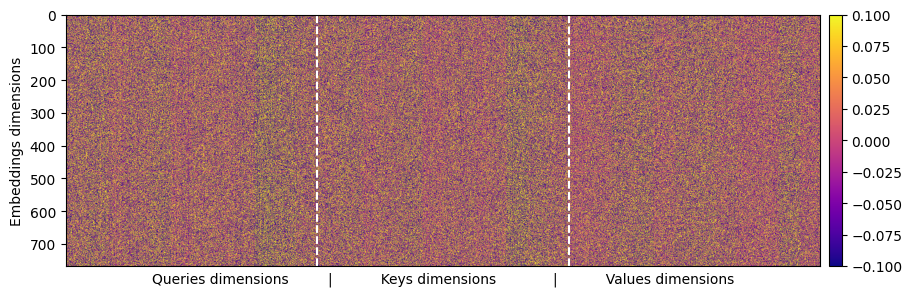

In [9]:

# in one layer for one model
whichmod = 'small'
layeri = 6

# extract the wide weights matrix for this layer
wide_weights = models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach()

plt.figure(figsize=(10,3))
plt.imshow(wide_weights,vmin=-.1,vmax=.1,cmap='plasma')
plt.axvline(params[whichmod]['n_emb'],linestyle='--',color='w')
plt.axvline(2*params[whichmod]['n_emb'],linestyle='--',color='w')
plt.colorbar(pad=.01)

plt.gca().set(xticks=[],ylabel='Embeddings dimensions',
              xlabel='Queries dimensions         |           Keys dimensions             |           Values dimensions')


plt.tight_layout()
plt.show()

In [10]:
wide_weights.shape

torch.Size([768, 2304])

## Task_2:
- Split the wide matrix you just extracted into WQ, WK, and WV
matrices. Calculate histograms of the values in each matrix, and
visualize as line plots as in Figure 6.2.
Next, extract those histograms in a for-loop over all layers.
Use the same bin boundaries for all layers, and store the histogram
density values in a matrix of size 12 × N × 3, where 12 corresponds
to the number of transformer layers, N is the number of bins in your
histogram (I used 81), and 3 corresponds to the WQ, WK, and WV
matrices. Show the results in a heatmap as in Figure 6.3, in which
the rows (y-axis) are transformer layers, the columns (x-axis) are the
weights values, and color is the density (the height in the histogram).
Finally, extract the mean and standard deviation of each weights
matrix and show the results in scatter plots as in Figure 6.4.

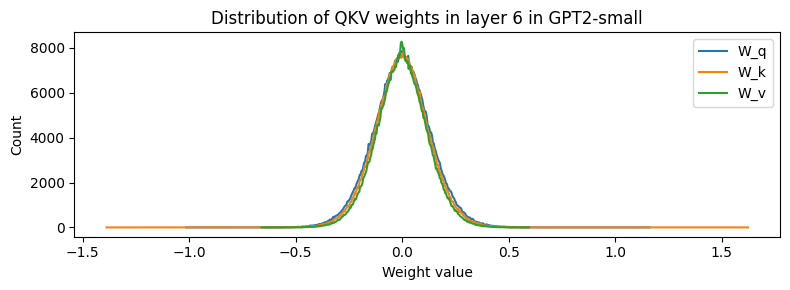

In [11]:
# split the Q, K, and V matrices
q,k,v = torch.split(wide_weights,params[whichmod]['n_emb'],dim=1)

# histograms of the three weights values
plt.figure(figsize=(8,3))
y,x = np.histogram(q.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_q')

y,x = np.histogram(k.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_k')

y,x = np.histogram(v.flatten(),bins='fd')
plt.plot(x[:-1],y,label='W_v')

plt.gca().set(xlabel='Weight value',ylabel='Count',
              title=f'Distribution of QKV weights in layer {layeri} in GPT2-{whichmod}')
plt.legend()

plt.tight_layout()
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1717/2924777783.py:30: SyntaxWarning: invalid escape sequence '\m'
  axs[i].set(xlabel='Weight value',ylabel='Layer',title=f"$\mathbf{{W}}_{'QKV'[i]}$")


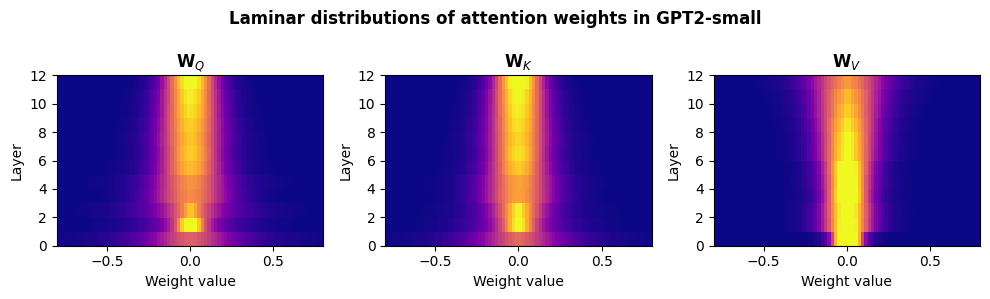

In [12]:
# common histogram boundaries
histedges = np.linspace(-.8,.8,81)

# initializations
distributions = np.zeros((params[whichmod]['n_layers'],len(histedges)-1,3))
distchars = np.zeros((params[whichmod]['n_layers'],2,3))

# loop over layers
for layeri in range(params[whichmod]['n_layers']):

  # split into matrices
  wideW = models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach()
  q,k,v = torch.split(wideW,params[whichmod]['n_emb'],dim=1)

  # histograms
  distributions[layeri,:,0] = np.histogram(q.flatten(),bins=histedges,density=True)[0]
  distributions[layeri,:,1] = np.histogram(k.flatten(),bins=histedges,density=True)[0]
  distributions[layeri,:,2] = np.histogram(v.flatten(),bins=histedges,density=True)[0]

  # mean and std
  distchars[layeri,:,0] = np.array([q.mean(), q.std()])
  distchars[layeri,:,1] = np.array([k.mean(), k.std()])
  distchars[layeri,:,2] = np.array([v.mean(), v.std()])

# show the heatmaps
_,axs = plt.subplots(1,3,figsize=(10,3))
for i in range(3):
  axs[i].imshow(distributions[:,:,i],origin='lower',extent=[histedges[0],histedges[-1],0,params[whichmod]['n_layers']],
                aspect='auto',cmap=plt.cm.plasma,vmin=0,vmax=3.5)
  axs[i].set(xlabel='Weight value',ylabel='Layer',title=f"$\mathbf{{W}}_{'QKV'[i]}$")

plt.suptitle(f'Laminar distributions of attention weights in GPT2-{whichmod}',fontweight='bold')


plt.tight_layout()
plt.show()


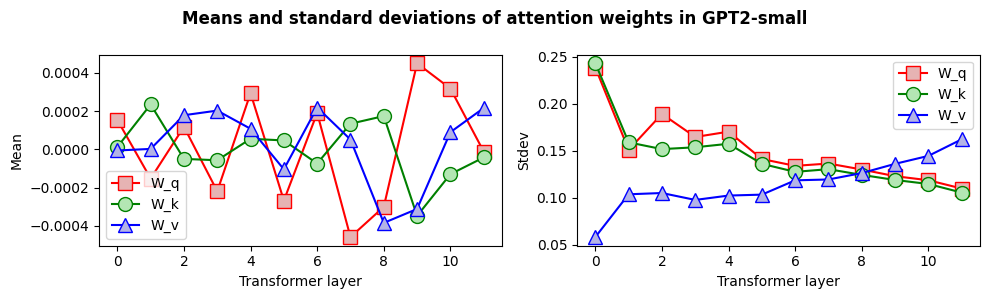

In [13]:

_,axs = plt.subplots(1,2,figsize=(10,3))

for i in [0,1]:
  axs[i].plot(distchars[:,i,0],'rs-',markerfacecolor=[.9,.7,.7],markersize=10)
  axs[i].plot(distchars[:,i,1],'go-',markerfacecolor=[.7,.9,.7],markersize=10)
  axs[i].plot(distchars[:,i,2],'b^-',markerfacecolor=[.7,.7,.9],markersize=10)
  axs[i].legend(['W_q','W_k','W_v'])
  axs[i].set(xlabel='Transformer layer',ylabel=['Mean','Stdev'][i])

plt.suptitle(f'Means and standard deviations of attention weights in GPT2-{whichmod}',fontweight='bold')


plt.tight_layout()
plt.show()

# Part 3: Comparing distributions across models

## Task_1:
- Loop over the four model variants, and over all layers within
each model. Split the attention weights into the WQ, WK, and
WV matrices, and calculate and store their means and standard
deviations.
Visualize the descriptive characteristics using line plots for each
model as in Figure 6.5. What features seem consistent across
models? Base your answer on visual inspection; you don’t need to
do any quantitative analyses.

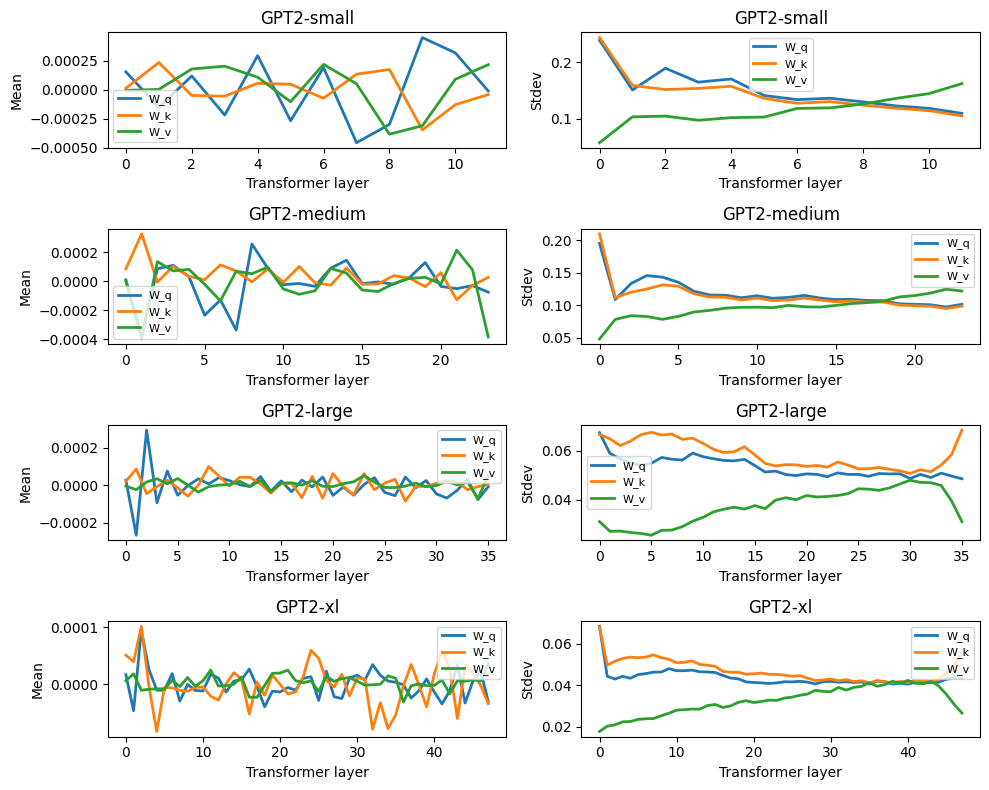

In [14]:
_,axs = plt.subplots(len(models),2,figsize=(10,8))


# loop over models
for modeli,whichmod in enumerate(models.keys()):

  # initialize matrix of statistics for this layer
  attn_stats = np.zeros((params[whichmod]['n_layers'],3,2))

  # loop over layers
  for layeri in range(params[whichmod]['n_layers']):

    # split into Q, K, V
    Q,K,V = torch.split(models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach(),
                        params[whichmod]['n_emb'],dim=1)

    ### Q
    attn_stats[layeri,0,0] = Q.mean()
    attn_stats[layeri,0,1] = Q.std()

    ### K
    attn_stats[layeri,1,0] = K.mean()
    attn_stats[layeri,1,1] = K.std()

    ### V
    attn_stats[layeri,2,0] = V.mean()
    attn_stats[layeri,2,1] = V.std()

  # end of layer loop

  for i in [0,1]:
    axs[modeli,i].plot(attn_stats[:,0,i],linewidth=2,label='W_q')
    axs[modeli,i].plot(attn_stats[:,1,i],linewidth=2,label='W_k')
    axs[modeli,i].plot(attn_stats[:,2,i],linewidth=2,label='W_v')
    axs[modeli,i].legend(fontsize=8)
    axs[modeli,i].set(xlabel='Transformer layer',ylabel=['Mean','Stdev'][i],
                      title=f'GPT2-{whichmod}')


plt.tight_layout()
plt.show()

# Part 4: Cosine similarity within heads (one model)

## Task_1:
- Use GPT-2-small. Create two list variables called WQ_h and WK_h in
which each element of the list is one attention head from one layer (I
used layer index 6). Confirm that the number of tensors in the list
equals the number of heads, and that the size of each head equals
the embeddings dimensionality times the head dimensionality.
Visualize the heads weights matrices as in Figure 6.6 (I used
the plasma color map). Make sure you have the correct orientation
(embeddings on the x-axis, head dimension on the y-axis)

In [15]:

whichmod = 'small'
layeri = 6

# to split into heads, first split into QKV
Q,K,V = torch.split(models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach(),
                    params[whichmod]['n_emb'],dim=1)

# now split each W matrix into heads
WQ_h = torch.split(Q,params[whichmod]['head_dim'],dim=1)
WK_h = torch.split(K,params[whichmod]['head_dim'],dim=1)

len(WQ_h), WQ_h[3].shape

(12, torch.Size([768, 64]))

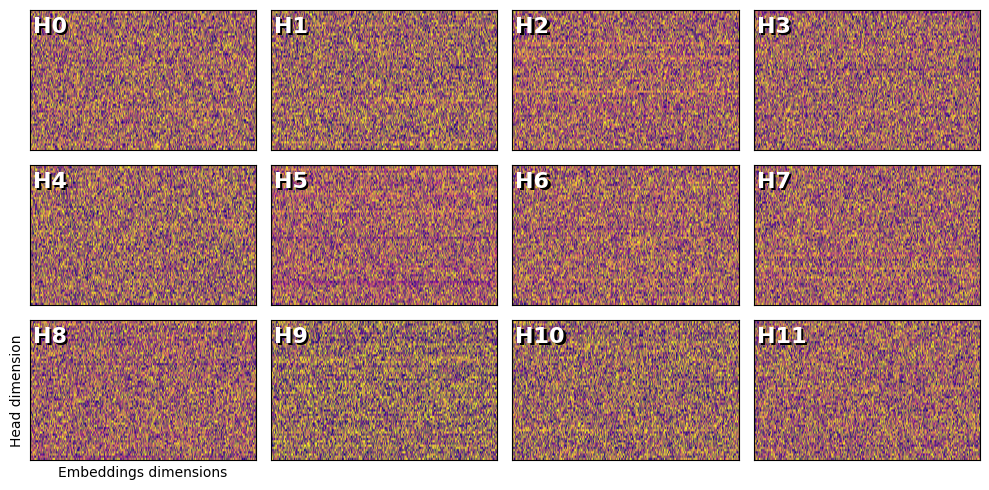

In [17]:

fig,axs = plt.subplots(3,4,figsize=(10,5))

axs = axs.flatten()
for i in range(len(WQ_h)):
  axs[i].imshow(WQ_h[i].T,aspect='auto',vmin=-.1,vmax=.1,cmap='plasma')
  axs[i].set(xticks=[],yticks=[])
  axs[i].text(18,11,f'H{i}',fontweight='bold',color='k',fontsize=16)
  axs[i].text(10,10,f'H{i}',fontweight='bold',color='w',fontsize=16)

axs[8].set(xlabel='Embeddings dimensions',ylabel='Head dimension')


plt.tight_layout()
plt.show()

## Task_2:
- Calculate the cosine similarity matrix of one head. Make sure the
matrix is 64 × 64; thus, each element is the pairwise similarity over
all embeddings dimensions for each head dimension.
Show the matrix as a heatmap, and show the non-redundant
and non-trivial elements of the matrix as a histogram, as in Figure
6.7.

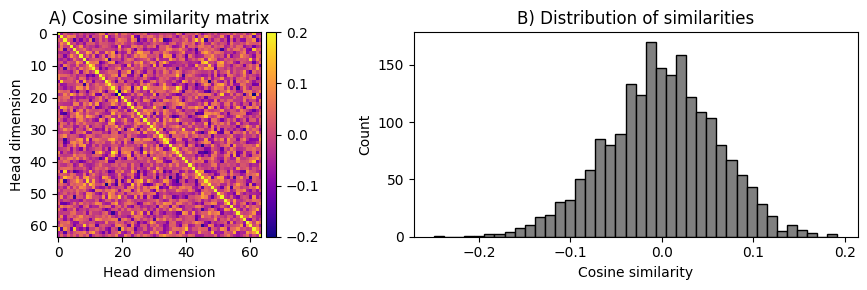

In [18]:

# cosine similarity in one attention head
tmp = WQ_h[0] / torch.norm(WQ_h[0],dim=0,keepdim=True)
cs_Q = tmp.T @ tmp

fig,axs = plt.subplots(1,2,figsize=(10,3))
# show the similarity matrix
h = axs[0].imshow(cs_Q,cmap='plasma',vmin=-.2,vmax=.2)
axs[0].set(xlabel='Head dimension',ylabel='Head dimension',title='A) Cosine similarity matrix')
fig.colorbar(h,ax=axs[0],pad=.01)

# and the distribution
axs[1].hist(cs_Q[np.triu_indices(cs_Q.shape[0],1)],40,color='gray',edgecolor='k')
axs[1].set(xlabel='Cosine similarity',ylabel='Count',title='B) Distribution of similarities')

plt.tight_layout()
plt.show()


# Part 5: Cosine similarity within- vs. across-heads (one model)

## Task_1:
- Inside a double-for loop over all heads (still just using matrices
from one layer), calculate the cosine similarities between all vectors
in head i with vectors in head j. Extract the non-redundant
similarity values and store them across all pairs. Be mindful that
the within-head similarity matrix contains redundant and trivial
values whereas the across-head similarity matrix does not. That is,
Sc(ik,jk) = Sc(jk,ik) only when ik and jk come from the same head.
Run these calculations for the WQ and WK vectors.
Visualize the results using histograms as in Figure 6.8.

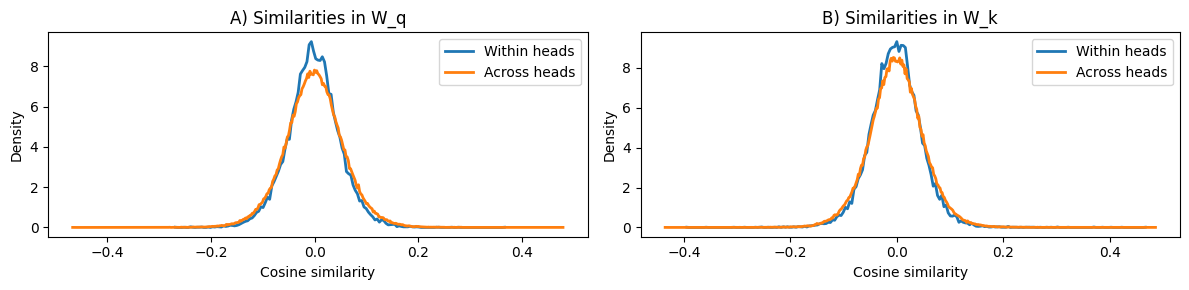

In [20]:
# initialize as empty arrays
withinhead_csQ = np.array([])
acrosshead_csQ = np.array([])
withinhead_csK = np.array([])
acrosshead_csK = np.array([])

# loop over pairs of heads
for i in range(params[whichmod]['n_heads']):
  for j in range(i,params[whichmod]['n_heads']):

    ### Q
    tmpi = WQ_h[i] / torch.norm(WQ_h[i],dim=0,keepdim=True)
    tmpj = WQ_h[j] / torch.norm(WQ_h[j],dim=0,keepdim=True)
    cs = (tmpi.T @ tmpj).numpy() # convert to numpy here...

    # store in the appropriate matrix
    if i==j: # within-head -> symmetric matrix -> keep nonredundant values
      cs = cs[np.triu_indices(params[whichmod]['head_dim'],k=1)]
      withinhead_csQ = np.concatenate((withinhead_csQ,cs))
    else: # across-head -> nonsymmetric matrix -> keep all values
      acrosshead_csQ = np.concatenate((acrosshead_csQ,cs.flatten()))


    ### K
    tmpi = WK_h[i] / torch.norm(WK_h[i],dim=0,keepdim=True)
    tmpj = WK_h[j] / torch.norm(WK_h[j],dim=0,keepdim=True)
    cs = tmpi.T @ tmpj # leave as pytorch here...

    # store in the appropriate matrix
    if i==j: # within-head -> symmetric matrix -> keep nonredundant values
      cs = cs[np.triu_indices(params[whichmod]['head_dim'],k=1)]
      withinhead_csK = np.concatenate((withinhead_csK,cs))
    else: # across-head -> nonsymmetric matrix -> keep all values
      acrosshead_csK = np.concatenate((acrosshead_csK,cs.flatten()))


_,axs = plt.subplots(1,2,figsize=(12,3))
y,x = np.histogram(withinhead_csQ,bins='fd',density=True)
axs[0].plot(x[:-1],y,linewidth=2,label='Within heads')
y,x = np.histogram(acrosshead_csQ,bins='fd',density=True)
axs[0].plot(x[:-1],y,linewidth=2,label='Across heads')
axs[0].set(xlabel='Cosine similarity',ylabel='Density',title='A) Similarities in W_q')
axs[0].legend()

y,x = np.histogram(withinhead_csK,bins='fd',density=True)
axs[1].plot(x[:-1],y,linewidth=2,label='Within heads')
y,x = np.histogram(acrosshead_csK,bins='fd',density=True)
axs[1].plot(x[:-1],y,linewidth=2,label='Across heads')
axs[1].set(xlabel='Cosine similarity',ylabel='Density',title='B) Similarities in W_k')
axs[1].legend()

plt.tight_layout()
plt.show()

## Task_2:
- Copy the code from above into a new code block, and place it
inside a for-loop over layers. Be mindful of what code needs to
be adjusted (e.g., extracting each layer’s weights matrices). Use
common histogram bins of 101 linearly spaced numbers between-.4 and .4 for all distributions. Calculate the mean and standard
deviations for the cosine similarities within-head and across-heads,
for WQ and WK.
Plot the distributions as heatmaps as in Figure 6.9 (use the
same color limits for all images), and plot the means and standard
deviations as line plots as in Figure 6.10

In [21]:
meenz = np.zeros((params[whichmod]['n_layers'],2,2))
stdez = np.zeros((params[whichmod]['n_layers'],2,2))

histbins = np.linspace(-.4,.4,101)
hists = np.zeros((params[whichmod]['n_layers'],len(histbins)-1,2,2))


# loop over all layers
for layeri in range(params[whichmod]['n_layers']):

  # split into heads
  Q,K,V = torch.split(models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach(),
                      params[whichmod]['n_emb'],dim=1)
  WQ_h = torch.split(Q,params[whichmod]['head_dim'],dim=1)
  WK_h = torch.split(K,params[whichmod]['head_dim'],dim=1)

  # re-initialize
  withinhead_csQ = np.array([])
  acrosshead_csQ = np.array([])
  withinhead_csK = np.array([])
  acrosshead_csK = np.array([])

  # loop over pairs of heads (copy from proj35)
  for i in range(params[whichmod]['n_heads']):
    for j in range(i,params[whichmod]['n_heads']):

      ### Q
      tmpi = WQ_h[i] / torch.norm(WQ_h[i],dim=0,keepdim=True)
      tmpj = WQ_h[j] / torch.norm(WQ_h[j],dim=0,keepdim=True)
      cs = (tmpi.T @ tmpj).numpy()

      # store in the appropriate matrix
      if i==j: # within-head -> symmetric matrix -> keep nonredundant values
        cs = cs[np.triu_indices(params[whichmod]['head_dim'],k=1)]
        withinhead_csQ = np.concatenate((withinhead_csQ,cs))
      else: # across-head -> nonsymmetric matrix -> keep all values
        acrosshead_csQ = np.concatenate((acrosshead_csQ,cs.flatten()))


      ### repeat for K
      tmpi = WK_h[i] / torch.norm(WK_h[i],dim=0,keepdim=True)
      tmpj = WK_h[j] / torch.norm(WK_h[j],dim=0,keepdim=True)
      cs = tmpi.T @ tmpj

      # store in the appropriate matrix
      if i==j: # within-head -> symmetric matrix -> keep nonredundant values
        cs = cs[np.triu_indices(params[whichmod]['head_dim'],k=1)]
        withinhead_csK = np.concatenate((withinhead_csK,cs))
      else: # across-head -> nonsymmetric matrix -> keep all values
        acrosshead_csK = np.concatenate((acrosshead_csK,cs.flatten()))
  # end of layer-loop

  # get the histograms
  hists[layeri,:,0,0] = np.histogram(withinhead_csQ,bins=histbins,density=True)[0]
  hists[layeri,:,1,0] = np.histogram(acrosshead_csQ,bins=histbins,density=True)[0]
  hists[layeri,:,0,1] = np.histogram(withinhead_csK,bins=histbins,density=True)[0]
  hists[layeri,:,1,1] = np.histogram(acrosshead_csK,bins=histbins,density=True)[0]

  # the means
  meenz[layeri,0,0] = withinhead_csQ.mean()
  meenz[layeri,0,1] = acrosshead_csQ.mean()
  meenz[layeri,1,0] = withinhead_csK.mean()
  meenz[layeri,1,1] = acrosshead_csK.mean()

  # and the standard deviations
  stdez[layeri,0,0] = withinhead_csQ.std()
  stdez[layeri,0,1] = acrosshead_csQ.std()
  stdez[layeri,1,0] = withinhead_csK.std()
  stdez[layeri,1,1] = acrosshead_csK.std()


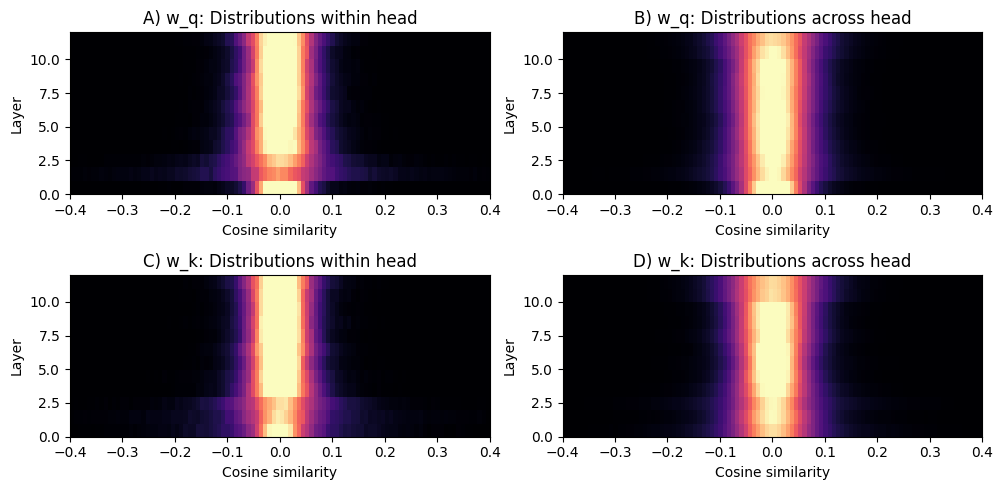

In [23]:
fig,axs = plt.subplots(2,2,figsize=(10,5))

# Q within-head
axs[0,0].imshow(hists[:,:,0,0],aspect='auto',vmin=0,vmax=7,cmap='magma',
              origin='lower',extent=[histbins[0],histbins[-1],0,params[whichmod]['n_layers']])
axs[0,0].set(xlabel='Cosine similarity',ylabel='Layer',title='A) w_q: Distributions within head')


# Q across-head
axs[0,1].imshow(hists[:,:,1,0],aspect='auto',vmin=0,vmax=7,cmap='magma',
              origin='lower',extent=[histbins[0],histbins[-1],0,params[whichmod]['n_layers']])
axs[0,1].set(xlabel='Cosine similarity',ylabel='Layer',title='B) w_q: Distributions across head')


# K within-head
axs[1,0].imshow(hists[:,:,0,1],aspect='auto',vmin=0,vmax=7,cmap='magma',
              origin='lower',extent=[histbins[0],histbins[-1],0,params[whichmod]['n_layers']])
axs[1,0].set(xlabel='Cosine similarity',ylabel='Layer',title='C) w_k: Distributions within head')


# K across-head
axs[1,1].imshow(hists[:,:,1,1],aspect='auto',vmin=0,vmax=7,cmap='magma',
              origin='lower',extent=[histbins[0],histbins[-1],0,params[whichmod]['n_layers']])
axs[1,1].set(xlabel='Cosine similarity',ylabel='Layer',title='D) w_k: Distributions across head')


plt.tight_layout()
plt.show()

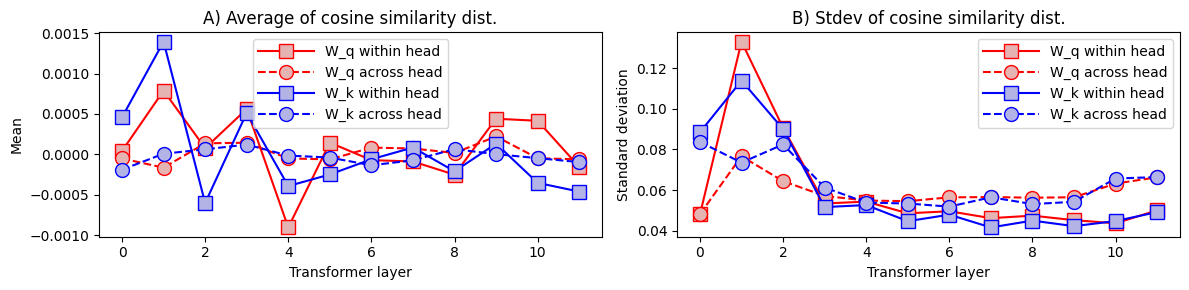

In [24]:
_,axs = plt.subplots(1,2,figsize=(12,3))

axs[0].plot(meenz[:,0,0],'rs-', markerfacecolor=[.9,.7,.7],markersize=10,label='W_q within head')
axs[0].plot(meenz[:,0,1],'ro--',markerfacecolor=[.9,.7,.7],markersize=10,label='W_q across head')
axs[0].plot(meenz[:,1,0],'bs-', markerfacecolor=[.7,.7,.9],markersize=10,label='W_k within head')
axs[0].plot(meenz[:,1,1],'bo--',markerfacecolor=[.7,.7,.9],markersize=10,label='W_k across head')
axs[0].legend(handlelength=4)
axs[0].set(xlabel='Transformer layer',ylabel='Mean',title='A) Average of cosine similarity dist.')

axs[1].plot(stdez[:,0,0],'rs-', markerfacecolor=[.9,.7,.7],markersize=10,label='W_q within head')
axs[1].plot(stdez[:,0,1],'ro--',markerfacecolor=[.9,.7,.7],markersize=10,label='W_q across head')
axs[1].plot(stdez[:,1,0],'bs-', markerfacecolor=[.7,.7,.9],markersize=10,label='W_k within head')
axs[1].plot(stdez[:,1,1],'bo--',markerfacecolor=[.7,.7,.9],markersize=10,label='W_k across head')
axs[1].legend(handlelength=4) # make the legend lines longer to show dashed vs solid
axs[1].set(xlabel='Transformer layer',ylabel='Standard deviation',title='B) Stdev of cosine similarity dist.')

plt.tight_layout()
plt.show()

# Part_6:W_q,W_k,W_v similarites across models

## Task_1:
- Loop over the four models, and loop over all transformer layers
within each model. Inside that double-for loop, extract the WQ,
WK, and WV matrices, calculate each cosine similarity matrix, and
store the mean and standard deviation.
Inside the inner loop, print out status updates for each layer
like the following:
Working on GPT-2-small (12 layers):
0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
Visualize the results as a collection of line plots where the rows cor
respond to the GPT-2 variants and the columns correspond to the
statistic (mean or standard deviation), as in Figure 6.11.



Working on GPT-2-small (12 layers):
0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 

Working on GPT-2-medium (24 layers):
0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 

Working on GPT-2-large (36 layers):
0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 

Working on GPT-2-xl (48 layers):
0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 

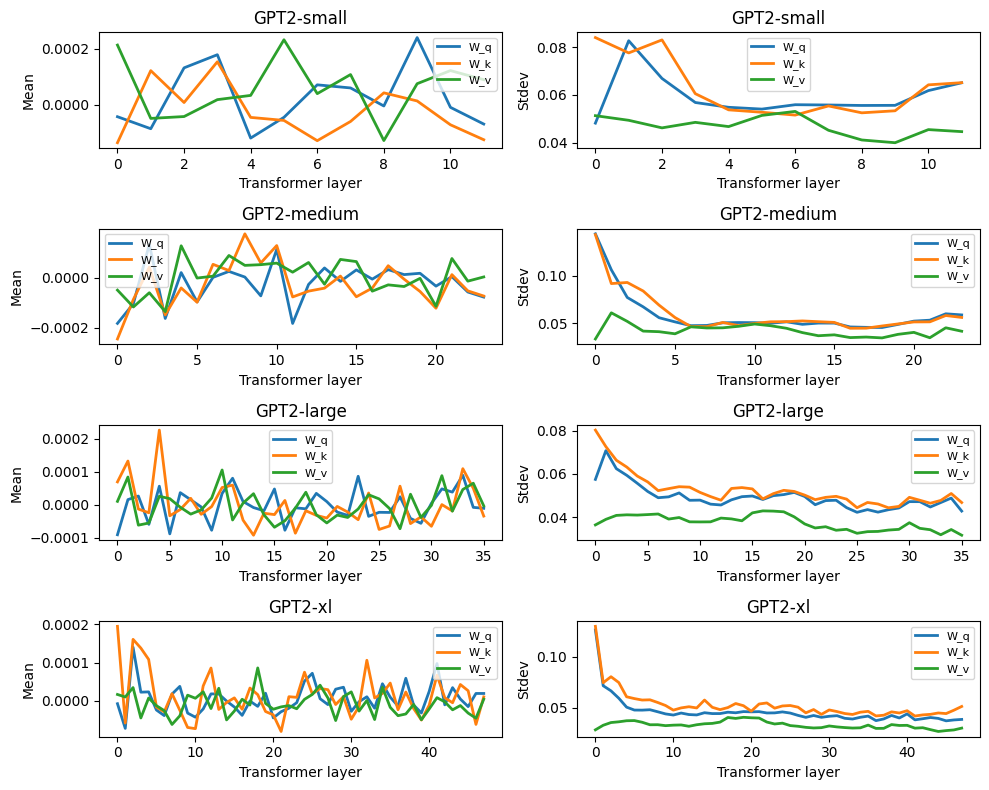

In [25]:
_,axs = plt.subplots(len(models),2,figsize=(10,8))


# loop over models
for modeli,whichmod in enumerate(models.keys()):

  # initialize matrix to store the metaparameters
  cossim_stats = np.zeros((params[whichmod]['n_layers'],3,2))

  # start of the progress report
  print(f"\n\nWorking on GPT-2-{whichmod} ({params[whichmod]['n_layers']} layers):")

  # mask for non-redundant and non-trivial indices
  # it is model-specific but not layer-specific
  N = params[whichmod]['n_emb']
  mask = torch.triu(torch.ones(N,N,dtype=torch.bool),diagonal=1)


  # loop over layers
  for layeri in range(params[whichmod]['n_layers']):

    # update the layer number in the progress report
    print(f'{layeri},',end=' ')

    # split into Q, K, V
    Q,K,V = torch.split(models[whichmod].transformer.h[layeri].attn.c_attn.weight.detach(),
                        params[whichmod]['n_emb'],dim=1)

    ### Q
    Q = Q / torch.norm(Q,dim=0,keepdim=True)
    cs = Q.T @ Q
    cs = cs[mask]
    cossim_stats[layeri,0,0] = cs.mean().item() # .item() to extract float from torch tensor
    cossim_stats[layeri,0,1] = cs.std().item()


    ### repeat for K
    K = K / torch.norm(K,dim=0,keepdim=True)
    cs = K.T @ K
    cs = cs[mask]
    cossim_stats[layeri,1,0] = cs.mean().item()
    cossim_stats[layeri,1,1] = cs.std().item()


    ### and for V
    V = V / torch.norm(V,dim=0,keepdim=True)
    cs = V.T @ V
    cs = cs[mask]
    cossim_stats[layeri,2,0] = cs.mean().item()
    cossim_stats[layeri,2,1] = cs.std().item()

  # end of layer loop

  for i in [0,1]:
    axs[modeli,i].plot(cossim_stats[:,0,i],linewidth=2,label='W_q')
    axs[modeli,i].plot(cossim_stats[:,1,i],linewidth=2,label='W_k')
    axs[modeli,i].plot(cossim_stats[:,2,i],linewidth=2,label='W_v')
    axs[modeli,i].legend(fontsize=8)
    axs[modeli,i].set(xlabel='Transformer layer',ylabel=['Mean','Stdev'][i],
                      title=f'GPT2-{whichmod}')


plt.tight_layout()
plt.savefig('ch6_proj33_part6.png')
plt.show()
